# SMOTE for Survival Analysis + Cox Model

This notebook implements:
1. **SMOTE for Survival Data**: Balances event/censored observations using survival-specific SMOTE
2. **Cox Proportional Hazards Model**: Standard survival analysis model
3. **Comprehensive Evaluation**: C-Index, IPCW C-Index, Brier score, KM curves

## Why SMOTE for Survival?
- Handles **class imbalance** between events and censored observations
- Preserves **survival time information** during oversampling
- Improves model discrimination for rare events

In [1]:
# Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler

# Survival analysis
from sksurv.linear_model import CoxPHSurvivalAnalysis, CoxnetSurvivalAnalysis
from sksurv.metrics import (
    concordance_index_censored,
    concordance_index_ipcw,
    brier_score,
    cumulative_dynamic_auc
)
from sksurv.util import Surv
from lifelines import KaplanMeierFitter
from lifelines.statistics import logrank_test

# SMOTE for imbalanced data
from imblearn.over_sampling import SMOTE, BorderlineSMOTE, ADASYN

import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")

print("✓ Libraries loaded successfully")

✓ Libraries loaded successfully


## Load Data

In [2]:
dataset = pd.read_csv("data/before_continuous/data_treated_nopr.csv")

diagnosis_variables = []

with open("data/before_continuous/diagnosis.txt", "r") as file:
    for line in file:
        diagnosis_variables.append(line.strip())

treatment_variables = []
with open("data/before_continuous/treatment.txt", "r") as file:
    for line in file:
        treatment_variables.append(line.strip())

survival_dataset = dataset.drop('Unnamed: 0', axis=1)

feature_columns = treatment_variables + diagnosis_variables

In [3]:
# Find duplicated patients with regional ln recurrence = 1
mask = (survival_dataset.duplicated(subset='PERSON_ID', keep=False)) #& (survival_dataset['Regional LN recurrence'] == 1)

# For each duplicated PERSON_ID with recurrence, keep only the row with the lowest survival days
to_remove = (
    survival_dataset[mask]
    .sort_values(['PERSON_ID', 'Survival days'], ascending=[True, True])
    .groupby('PERSON_ID')
    .head(-1)
    .index
)

survival_dataset = survival_dataset.drop(to_remove)

In [4]:
# Prepare data
data_x = survival_dataset[feature_columns]

data_y = Surv.from_arrays(
    event=survival_dataset['Regional LN recurrence'],
    time=survival_dataset['Survival days']
)
# Since every duplicated patient has a consistent event indicator (regional ln recurrence) I can use this method
groups = survival_dataset['PERSON_ID']

In [5]:
sgkf = StratifiedKFold(n_splits=5, shuffle=True, random_state=12)
cv = sgkf.split(X=data_x, y=survival_dataset['Regional LN recurrence'])

train_index, test_index = next(cv)

In [6]:
x_train = data_x.iloc[train_index]
y_train = data_y[train_index]

x_test = data_x.iloc[test_index]
y_test = data_y[test_index]

In [7]:
# Extract event and time arrays from structured survival data
event_train = y_train['event'].astype(int)
time_train = y_train['time']

event_test = y_test['event'].astype(int)
time_test = y_test['time']

# Standardize features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(x_train)
X_test_scaled = scaler.transform(x_test)

print(f"✓ Features standardized (mean=0, std=1)")
print(f"  Training samples: {len(X_train_scaled)}")
print(f"  Test samples: {len(X_test_scaled)}")
print(f"  Training events: {event_train.sum()} ({event_train.mean()*100:.1f}%)")
print(f"  Test events: {event_test.sum()} ({event_test.mean()*100:.1f}%)")

✓ Features standardized (mean=0, std=1)
  Training samples: 2376
  Test samples: 594
  Training events: 27 (1.1%)
  Test events: 6 (1.0%)


## Apply SMOTE for Survival Data

SMOTE (Synthetic Minority Over-sampling Technique) creates synthetic samples for the minority class (events) by:
1. Finding k-nearest neighbors for each minority sample
2. Creating synthetic samples along the lines between neighbors
3. Balancing the event/censored ratio

**Note**: We only apply SMOTE to training data to avoid data leakage!

In [8]:
# Apply SMOTE to balance event/censored observations
# NOTE: This cell will be updated after finding the best SMOTE configuration
# For now, we use default parameters (will be updated after hyperparameter tuning)
print("Applying SMOTE to training data...")
print(f"\nBefore SMOTE:")
print(f"  Events:    {event_train.sum()}")
print(f"  Censored:  {(1-event_train).sum()}")
print(f"  Ratio:     1:{(1-event_train).sum()/event_train.sum():.1f}")

# SMOTE with moderate oversampling (not full balance)
# sampling_strategy: 0.5 means minority class will be 50% of majority class
# NOTE: These parameters will be replaced with the best configuration found later
smote = SMOTE(
    sampling_strategy=0.5,  # Will be updated with best_smote_sampling_strategy
    random_state=42,
    k_neighbors=5  # Will be updated with best_smote_k_neighbors
)

# Concatenate features with time for SMOTE (preserve time-event relationship)
X_train_with_time = np.column_stack([X_train_scaled, time_train])

# Apply SMOTE
X_train_smote_with_time, event_train_smote = smote.fit_resample(
    X_train_with_time, 
    event_train.astype(int)
)

# Separate features and time after SMOTE
X_train_smote = X_train_smote_with_time[:, :-1]
time_train_smote = X_train_smote_with_time[:, -1]

print(f"\nAfter SMOTE:")
print(f"  Events:    {event_train_smote.sum()}")
print(f"  Censored:  {(1-event_train_smote).sum()}")
print(f"  Ratio:     1:{(1-event_train_smote).sum()/event_train_smote.sum():.1f}")
print(f"  Total samples: {len(X_train_smote)} (original: {len(X_train_scaled)})")
print(f"  Synthetic samples added: {len(X_train_smote) - len(X_train_scaled)}")

print(f"\n✓ SMOTE applied successfully!")
print(f"⚠️  NOTE: Run SMOTE hyperparameter tuning section to find optimal parameters")

Applying SMOTE to training data...

Before SMOTE:
  Events:    27
  Censored:  2349
  Ratio:     1:87.0

After SMOTE:
  Events:    1174
  Censored:  2349
  Ratio:     1:2.0
  Total samples: 3523 (original: 2376)
  Synthetic samples added: 1147

✓ SMOTE applied successfully!
⚠️  NOTE: Run SMOTE hyperparameter tuning section to find optimal parameters

After SMOTE:
  Events:    1174
  Censored:  2349
  Ratio:     1:2.0
  Total samples: 3523 (original: 2376)
  Synthetic samples added: 1147

✓ SMOTE applied successfully!
⚠️  NOTE: Run SMOTE hyperparameter tuning section to find optimal parameters


## Visualize SMOTE Effect

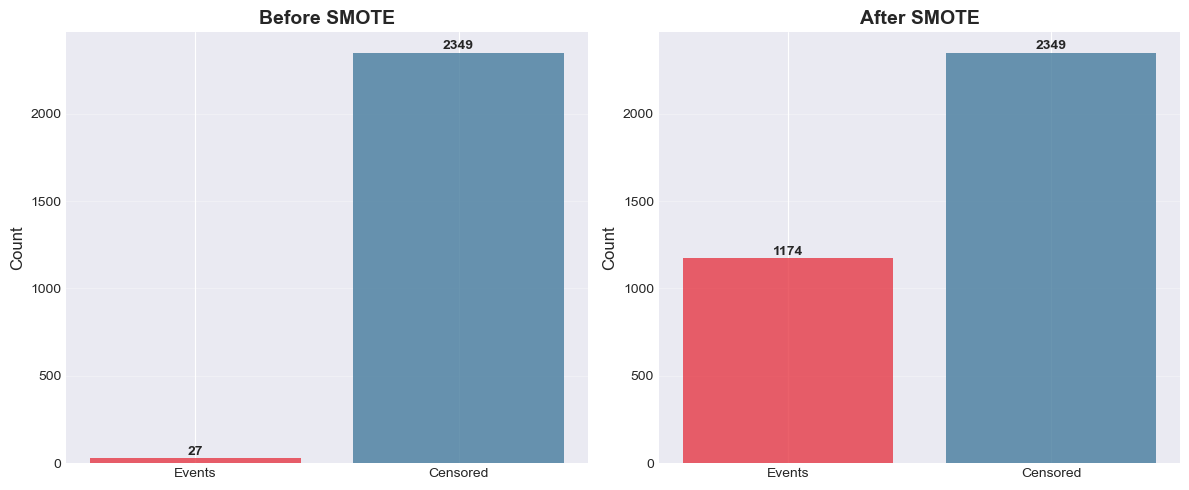

In [9]:
# Visualize class balance before and after SMOTE
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Before SMOTE
before_counts = [event_train.sum(), (1-event_train).sum()]
axes[0].bar(['Events', 'Censored'], before_counts, color=['#E63946', '#457B9D'], alpha=0.8)
axes[0].set_title('Before SMOTE', fontsize=14, fontweight='bold')
axes[0].set_ylabel('Count', fontsize=12)
axes[0].grid(axis='y', alpha=0.3)
for i, v in enumerate(before_counts):
    axes[0].text(i, v + 20, str(int(v)), ha='center', fontweight='bold')

# After SMOTE
after_counts = [event_train_smote.sum(), (1-event_train_smote).sum()]
axes[1].bar(['Events', 'Censored'], after_counts, color=['#E63946', '#457B9D'], alpha=0.8)
axes[1].set_title('After SMOTE', fontsize=14, fontweight='bold')
axes[1].set_ylabel('Count', fontsize=12)
axes[1].grid(axis='y', alpha=0.3)
for i, v in enumerate(after_counts):
    axes[1].text(i, v + 20, str(int(v)), ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

## Cox Model WITHOUT SMOTE (Baseline)

In [ ]:
# Cross-validation to find the best alpha for baseline model
print("Running cross-validation for BASELINE model (no SMOTE)...")
print("Using IPCW C-Index to select best alpha...")
print("NOTE: Scaling is performed INSIDE each fold to prevent data leakage")

# Define alpha grid (log-spaced values)
alphas_cv = np.logspace(-3, 1, 20)

# Create StratifiedKFold for CV
from sklearn.model_selection import StratifiedKFold
cv_folds = StratifiedKFold(n_splits=4, shuffle=True, random_state=42)

# Store CV results
cv_results_baseline = []

for alpha in alphas_cv:
    fold_scores_ipcw = []
    fold_scores_cindex = []
    
    for fold_idx, (train_idx, val_idx) in enumerate(cv_folds.split(x_train, event_train)):
        # Split into train/val (UNSCALED)
        X_cv_train = x_train.iloc[train_idx]
        X_cv_val = x_train.iloc[val_idx]
        y_cv_train = y_train[train_idx]
        y_cv_val = y_train[val_idx]
        
        # Scale INSIDE the fold to prevent data leakage
        scaler_fold = StandardScaler()
        X_cv_train_scaled = scaler_fold.fit_transform(X_cv_train)
        X_cv_val_scaled = scaler_fold.transform(X_cv_val)
        
        # Train model on SCALED data
        model = CoxnetSurvivalAnalysis(alphas=[alpha], l1_ratio=1.0, fit_baseline_model=True)
        model.fit(X_cv_train_scaled, y_cv_train)
        
        # Predict and evaluate on SCALED validation data
        risk_scores = model.predict(X_cv_val_scaled)
        
        # Calculate standard C-Index
        c_index = concordance_index_censored(
            y_cv_val['event'],
            y_cv_val['time'],
            risk_scores
        )[0]
        fold_scores_cindex.append(c_index)
        
        # Calculate tau for IPCW
        train_max_time = y_cv_train['time'].max()
        val_max_time = y_cv_val['time'].max()
        tau = 0.9 * min(train_max_time, val_max_time)
        
        # Calculate IPCW C-Index
        c_index_ipcw = concordance_index_ipcw(
            survival_train=y_cv_train,
            survival_test=y_cv_val,
            estimate=risk_scores,
            tau=tau
        )[0]
        fold_scores_ipcw.append(c_index_ipcw)
    
    mean_score_ipcw = np.mean(fold_scores_ipcw)
    std_score_ipcw = np.std(fold_scores_ipcw)
    mean_score_cindex = np.mean(fold_scores_cindex)
    std_score_cindex = np.std(fold_scores_cindex)
    
    cv_results_baseline.append({
        'alpha': alpha,
        'mean_c_index': mean_score_cindex,
        'std_c_index': std_score_cindex,
        'mean_c_index_ipcw': mean_score_ipcw,
        'std_c_index_ipcw': std_score_ipcw
    })

# Convert to DataFrame and find best alpha (using IPCW as primary metric)
cv_df_baseline = pd.DataFrame(cv_results_baseline)
best_idx_baseline = cv_df_baseline['mean_c_index_ipcw'].idxmax()
best_alpha_baseline = cv_df_baseline.loc[best_idx_baseline, 'alpha']
best_score_baseline = cv_df_baseline.loc[best_idx_baseline, 'mean_c_index_ipcw']
best_score_baseline_cindex = cv_df_baseline.loc[best_idx_baseline, 'mean_c_index']

print(f"\n{'='*60}")
print("BASELINE MODEL CV Results:")
print(f"{'='*60}")
print(f"Best alpha: {best_alpha_baseline:.4f}")
print(f"Best CV C-Index:      {best_score_baseline_cindex:.4f} ± {cv_df_baseline.loc[best_idx_baseline, 'std_c_index']:.4f}")
print(f"Best CV IPCW C-Index: {best_score_baseline:.4f} ± {cv_df_baseline.loc[best_idx_baseline, 'std_c_index_ipcw']:.4f}")
print(f"\nTop 5 alphas:")
print(cv_df_baseline.sort_values('mean_c_index_ipcw', ascending=False).head()[['alpha', 'mean_c_index', 'mean_c_index_ipcw', 'std_c_index', 'std_c_index_ipcw']])
print(f"{'='*60}")

Running cross-validation for BASELINE model (no SMOTE)...
Using IPCW C-Index to select best alpha...

BASELINE MODEL CV Results:
Best alpha: 0.0026
Best CV C-Index:      0.8561 ± 0.0986
Best CV IPCW C-Index: 0.6924 ± 0.2148

Top 5 alphas:
      alpha  mean_c_index  mean_c_index_ipcw  std_c_index  std_c_index_ipcw
2  0.002637      0.856098           0.692428     0.098622          0.214807
3  0.004281      0.840933           0.690317     0.104174          0.205537
1  0.001624      0.847139           0.688741     0.096072          0.202091
0  0.001000      0.836925           0.680916     0.098775          0.197021
4  0.006952      0.813415           0.663701     0.091550          0.188209

BASELINE MODEL CV Results:
Best alpha: 0.0026
Best CV C-Index:      0.8561 ± 0.0986
Best CV IPCW C-Index: 0.6924 ± 0.2148

Top 5 alphas:
      alpha  mean_c_index  mean_c_index_ipcw  std_c_index  std_c_index_ipcw
2  0.002637      0.856098           0.692428     0.098622          0.214807
3  0.004281    

In [70]:
# Train Cox model on original (unbalanced) data using best alpha from CV
print(f"Training Cox model WITHOUT SMOTE (baseline) with alpha={best_alpha_baseline:.4f}...")

# Create structured array for sksurv
y_train = Surv.from_arrays(event=event_train.astype(bool), time=time_train)
y_test = Surv.from_arrays(event=event_test.astype(bool), time=time_test)

# Train Cox model using Coxnet (Lasso regularization) with best alpha
cox_baseline = CoxnetSurvivalAnalysis(alphas=[best_alpha_baseline], l1_ratio=1.0, fit_baseline_model=True)
cox_baseline.fit(X_train_scaled, y_train)

# Predictions
train_risk_baseline = cox_baseline.predict(X_train_scaled)
test_risk_baseline = cox_baseline.predict(X_test_scaled)

# Evaluation
train_cindex_baseline = concordance_index_censored(
    event_train.astype(bool), time_train, train_risk_baseline
)[0]
test_cindex_baseline = concordance_index_censored(
    event_test.astype(bool), time_test, test_risk_baseline
)[0]

# IPCW C-Index - use explicit tau to avoid ambiguity
max_time_ipcw = min(y_train['time'].max(), y_test['time'].max()) * 0.9
test_cindex_ipcw_baseline, _, _, _, _ = concordance_index_ipcw(
    y_train, y_test, test_risk_baseline, tau=max_time_ipcw
)

# Report number of selected features
n_features_baseline = np.sum(cox_baseline.coef_.flatten() != 0)

print(f"\n{'='*60}")
print("Baseline Cox Model (WITHOUT SMOTE) Results")
print(f"{'='*60}")
print(f"Alpha used:          {best_alpha_baseline:.4f}")
print(f"Features selected:   {n_features_baseline}/{len(cox_baseline.coef_.flatten())}")
print(f"Train C-Index:       {train_cindex_baseline:.4f}")
print(f"Test C-Index:        {test_cindex_baseline:.4f}")
print(f"Test C-Index (IPCW): {test_cindex_ipcw_baseline:.4f}")
print(f"{'='*60}")

Training Cox model WITHOUT SMOTE (baseline) with alpha=0.0026...

Baseline Cox Model (WITHOUT SMOTE) Results
Alpha used:          0.0026
Features selected:   12/69
Train C-Index:       0.9250
Test C-Index:        0.8101
Test C-Index (IPCW): 0.6242


## Cox Model WITH SMOTE

### SMOTE Hyperparameter Tuning

Before training the SMOTE model, we'll tune SMOTE hyperparameters to find the optimal configuration. This is critical because:
1. **Extreme Class Imbalance**: With 1:89 ratio, default SMOTE might create unrealistic synthetic samples
2. **Sampling Strategy**: Different target ratios may work better than 50/50
3. **K-Neighbors**: Number of neighbors affects synthetic sample quality
4. **SMOTE Variants**: BorderlineSMOTE and ADASYN might handle extreme imbalance better

In [ ]:
# Hyperparameter tuning for SMOTE
print("="*80)
print("TUNING SMOTE HYPERPARAMETERS")
print("="*80)
print("Testing different SMOTE configurations to find optimal settings...")
print()

from imblearn.over_sampling import BorderlineSMOTE, ADASYN

# Define SMOTE hyperparameter grid
smote_configs = []

# 1. Different sampling strategies (target minority class ratios)
sampling_strategies = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7]

# 2. Different k_neighbors values
k_neighbors_values = [3, 5, 7, 10]

# 3. Different SMOTE variants
smote_variants = [
    ('SMOTE', SMOTE),
    ('BorderlineSMOTE', BorderlineSMOTE),
    ('ADASYN', ADASYN)
]

# Create all combinations
for variant_name, variant_class in smote_variants:
    for sampling_strategy in sampling_strategies:
        for k_neighbors in k_neighbors_values:
            smote_configs.append({
                'variant': variant_name,
                'variant_class': variant_class,
                'sampling_strategy': sampling_strategy,
                'k_neighbors': k_neighbors
            })

print(f"Total SMOTE configurations to test: {len(smote_configs)}")
print()

# Use a fixed alpha for SMOTE tuning (we'll use the best baseline alpha as reference)
fixed_alpha = best_alpha_baseline

# Test each SMOTE configuration with 2-fold CV (faster)
from sklearn.model_selection import StratifiedKFold
smote_tuning_cv = StratifiedKFold(n_splits=2, shuffle=True, random_state=42)

smote_tuning_results = []

for idx, config in enumerate(smote_configs):
    try:
        fold_scores = []
        
        for fold_idx, (train_idx, val_idx) in enumerate(smote_tuning_cv.split(x_train, event_train)):
            # Split data (UNSCALED)
            X_cv_train = x_train.iloc[train_idx]
            X_cv_val = x_train.iloc[val_idx]
            event_cv_train = event_train[train_idx]
            time_cv_train = time_train[train_idx]
            event_cv_val = event_train[val_idx]
            time_cv_val = time_train[val_idx]
            
            # Scale INSIDE the fold BEFORE applying SMOTE
            scaler_fold = StandardScaler()
            X_cv_train_scaled = scaler_fold.fit_transform(X_cv_train)
            X_cv_val_scaled = scaler_fold.transform(X_cv_val)
            
            # Apply SMOTE with current config on SCALED data
            X_cv_train_with_time = np.column_stack([X_cv_train_scaled, time_cv_train])
            
            if config['variant'] == 'ADASYN':
                # ADASYN uses n_neighbors instead of k_neighbors
                smote_obj = config['variant_class'](
                    sampling_strategy=config['sampling_strategy'],
                    n_neighbors=config['k_neighbors'],
                    random_state=42
                )
            else:
                smote_obj = config['variant_class'](
                    sampling_strategy=config['sampling_strategy'],
                    k_neighbors=config['k_neighbors'],
                    random_state=42
                )
            
            X_cv_train_smote_with_time, event_cv_train_smote = smote_obj.fit_resample(
                X_cv_train_with_time, event_cv_train
            )
            X_cv_train_smote = X_cv_train_smote_with_time[:, :-1]
            time_cv_train_smote = X_cv_train_smote_with_time[:, -1]
            
            # Create survival arrays
            y_cv_train_smote = Surv.from_arrays(
                event=event_cv_train_smote.astype(bool),
                time=time_cv_train_smote
            )
            y_cv_val = Surv.from_arrays(
                event=event_cv_val.astype(bool),
                time=time_cv_val
            )
            y_cv_train_orig = Surv.from_arrays(
                event=event_cv_train.astype(bool),
                time=time_cv_train
            )
            
            # Train model
            model = CoxnetSurvivalAnalysis(alphas=[fixed_alpha], l1_ratio=1.0, fit_baseline_model=True)
            model.fit(X_cv_train_smote, y_cv_train_smote)
            
            # Evaluate with IPCW C-Index on SCALED validation data
            risk_scores = model.predict(X_cv_val_scaled)
            train_max_time = time_cv_train.max()
            val_max_time = time_cv_val.max()
            tau = 0.9 * min(train_max_time, val_max_time)
            
            c_index_ipcw = concordance_index_ipcw(
                survival_train=y_cv_train_orig,
                survival_test=y_cv_val,
                estimate=risk_scores,
                tau=tau
            )[0]
            fold_scores.append(c_index_ipcw)
        
        # Store results
        mean_score = np.mean(fold_scores)
        std_score = np.std(fold_scores)
        
        smote_tuning_results.append({
            'variant': config['variant'],
            'sampling_strategy': config['sampling_strategy'],
            'k_neighbors': config['k_neighbors'],
            'mean_c_index_ipcw': mean_score,
            'std_c_index_ipcw': std_score
        })
        
        if (idx + 1) % 10 == 0:
            print(f"Tested {idx + 1}/{len(smote_configs)} configurations...")
            
    except Exception as e:
        # Skip configurations that fail (e.g., not enough neighbors)
        continue

print(f"\nCompleted! Successfully tested {len(smote_tuning_results)} configurations")

# Convert to DataFrame and find best configuration
smote_tuning_df = pd.DataFrame(smote_tuning_results)
best_smote_idx = smote_tuning_df['mean_c_index_ipcw'].idxmax()
best_smote_config = smote_tuning_df.loc[best_smote_idx]

print("\n" + "="*80)
print("BEST SMOTE CONFIGURATION:")
print("="*80)
print(f"Variant: {best_smote_config['variant']}")
print(f"Sampling Strategy: {best_smote_config['sampling_strategy']}")
print(f"K-Neighbors: {int(best_smote_config['k_neighbors'])}")
print(f"Mean IPCW C-Index: {best_smote_config['mean_c_index_ipcw']:.4f} ± {best_smote_config['std_c_index_ipcw']:.4f}")
print()

# Compare with baseline (no SMOTE)
print(f"Baseline (no SMOTE) CV score: {best_score_baseline:.4f}")
print(f"Best SMOTE configuration:      {best_smote_config['mean_c_index_ipcw']:.4f}")
print(f"Improvement:                   {best_smote_config['mean_c_index_ipcw'] - best_score_baseline:+.4f}")
print("="*80)
print()

# Show top 10 configurations
print("TOP 10 SMOTE CONFIGURATIONS:")
print(smote_tuning_df.sort_values('mean_c_index_ipcw', ascending=False).head(10).to_string(index=False))
print()

# Store best config for later use
best_smote_variant = best_smote_config['variant']
best_smote_sampling_strategy = best_smote_config['sampling_strategy']
best_smote_k_neighbors = int(best_smote_config['k_neighbors'])

TUNING SMOTE HYPERPARAMETERS
Testing different SMOTE configurations to find optimal settings...

Total SMOTE configurations to test: 84

Tested 10/84 configurations...
Tested 10/84 configurations...
Tested 20/84 configurations...
Tested 20/84 configurations...
Tested 40/84 configurations...
Tested 40/84 configurations...
Tested 50/84 configurations...
Tested 50/84 configurations...
Tested 60/84 configurations...
Tested 60/84 configurations...
Tested 70/84 configurations...
Tested 70/84 configurations...
Tested 80/84 configurations...
Tested 80/84 configurations...

Completed! Successfully tested 78 configurations

BEST SMOTE CONFIGURATION:
Variant: BorderlineSMOTE
Sampling Strategy: 0.5
K-Neighbors: 5
Mean IPCW C-Index: 0.8657 ± 0.0662

Baseline (no SMOTE) CV score: 0.6924
Best SMOTE configuration:      0.8657
Improvement:                   +0.1733

TOP 10 SMOTE CONFIGURATIONS:
        variant  sampling_strategy  k_neighbors  mean_c_index_ipcw  std_c_index_ipcw
BorderlineSMOTE         

In [72]:
# Apply BEST SMOTE configuration to full training set
print("="*80)
print("APPLYING BEST SMOTE CONFIGURATION TO TRAINING DATA")
print("="*80)

# Get the correct SMOTE class
if best_smote_variant == 'SMOTE':
    smote_class = SMOTE
elif best_smote_variant == 'BorderlineSMOTE':
    smote_class = BorderlineSMOTE
else:  # ADASYN
    smote_class = ADASYN

# Create SMOTE with best configuration
if best_smote_variant == 'ADASYN':
    smote_best = smote_class(
        sampling_strategy=best_smote_sampling_strategy,
        n_neighbors=best_smote_k_neighbors,
        random_state=42
    )
else:
    smote_best = smote_class(
        sampling_strategy=best_smote_sampling_strategy,
        k_neighbors=best_smote_k_neighbors,
        random_state=42
    )

print(f"\nApplying {best_smote_variant} with:")
print(f"  - Sampling strategy: {best_smote_sampling_strategy}")
print(f"  - K-neighbors: {best_smote_k_neighbors}")

print(f"\nBefore SMOTE:")
print(f"  Events:    {event_train.sum()}")
print(f"  Censored:  {(1-event_train).sum()}")
print(f"  Ratio:     1:{(1-event_train).sum()/event_train.sum():.1f}")

# Concatenate features with time for SMOTE (preserve time-event relationship)
X_train_with_time_best = np.column_stack([X_train_scaled, time_train])

# Apply SMOTE
X_train_smote_best_with_time, event_train_smote_best = smote_best.fit_resample(
    X_train_with_time_best, 
    event_train.astype(int)
)

# Separate features and time after SMOTE
X_train_smote_best = X_train_smote_best_with_time[:, :-1]
time_train_smote_best = X_train_smote_best_with_time[:, -1]

print(f"\nAfter SMOTE (BEST CONFIG):")
print(f"  Events:    {event_train_smote_best.sum()}")
print(f"  Censored:  {(1-event_train_smote_best).sum()}")
print(f"  Ratio:     1:{(1-event_train_smote_best).sum()/event_train_smote_best.sum():.1f}")
print(f"  Total samples: {len(X_train_smote_best)} (original: {len(X_train_scaled)})")
print(f"  Synthetic samples added: {len(X_train_smote_best) - len(X_train_scaled)}")

print(f"\n✓ Best SMOTE configuration applied successfully!")
print("="*80)

# Update the variables to use best configuration (for downstream cells)
X_train_smote = X_train_smote_best
event_train_smote = event_train_smote_best
time_train_smote = time_train_smote_best

APPLYING BEST SMOTE CONFIGURATION TO TRAINING DATA

Applying BorderlineSMOTE with:
  - Sampling strategy: 0.5
  - K-neighbors: 5

Before SMOTE:
  Events:    27
  Censored:  2349
  Ratio:     1:87.0

After SMOTE (BEST CONFIG):
  Events:    1174
  Censored:  2349
  Ratio:     1:2.0
  Total samples: 3523 (original: 2376)
  Synthetic samples added: 1147

✓ Best SMOTE configuration applied successfully!


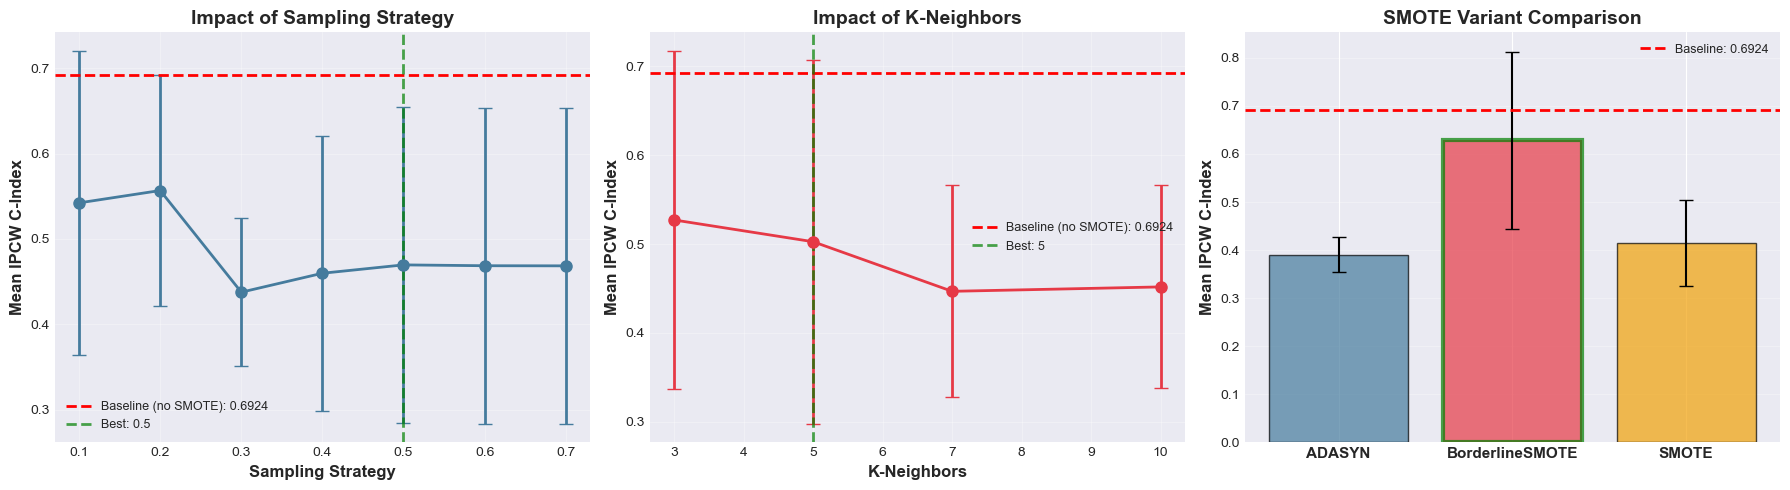


KEY INSIGHTS FROM SMOTE TUNING:
1. Best Sampling Strategy: 0.5 (lower is more conservative)
2. Best K-Neighbors: 5
3. Best Variant: BorderlineSMOTE
4. Best Configuration Performance: 0.8657
5. Baseline Performance: 0.6924
   ✓ SMOTE IMPROVES performance by +0.1733


In [73]:
# Visualize SMOTE hyperparameter tuning results
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot 1: Performance by Sampling Strategy (aggregated across all variants)
sampling_grouped = smote_tuning_df.groupby('sampling_strategy')['mean_c_index_ipcw'].agg(['mean', 'std'])
axes[0].errorbar(sampling_grouped.index, sampling_grouped['mean'], 
                 yerr=sampling_grouped['std'], fmt='o-', capsize=5, 
                 color='#457B9D', linewidth=2, markersize=8)
axes[0].axhline(best_score_baseline, color='red', linestyle='--', linewidth=2, 
                label=f'Baseline (no SMOTE): {best_score_baseline:.4f}')
axes[0].axvline(best_smote_sampling_strategy, color='green', linestyle='--', 
                linewidth=2, alpha=0.7, label=f'Best: {best_smote_sampling_strategy}')
axes[0].set_xlabel('Sampling Strategy', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Mean IPCW C-Index', fontsize=12, fontweight='bold')
axes[0].set_title('Impact of Sampling Strategy', fontsize=14, fontweight='bold')
axes[0].legend(fontsize=9)
axes[0].grid(alpha=0.3)

# Plot 2: Performance by K-Neighbors (aggregated across all variants)
k_grouped = smote_tuning_df.groupby('k_neighbors')['mean_c_index_ipcw'].agg(['mean', 'std'])
axes[1].errorbar(k_grouped.index, k_grouped['mean'], 
                 yerr=k_grouped['std'], fmt='o-', capsize=5, 
                 color='#E63946', linewidth=2, markersize=8)
axes[1].axhline(best_score_baseline, color='red', linestyle='--', linewidth=2, 
                label=f'Baseline (no SMOTE): {best_score_baseline:.4f}')
axes[1].axvline(best_smote_k_neighbors, color='green', linestyle='--', 
                linewidth=2, alpha=0.7, label=f'Best: {best_smote_k_neighbors}')
axes[1].set_xlabel('K-Neighbors', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Mean IPCW C-Index', fontsize=12, fontweight='bold')
axes[1].set_title('Impact of K-Neighbors', fontsize=14, fontweight='bold')
axes[1].legend(fontsize=9)
axes[1].grid(alpha=0.3)

# Plot 3: Performance by SMOTE Variant (aggregated across all parameters)
variant_grouped = smote_tuning_df.groupby('variant')['mean_c_index_ipcw'].agg(['mean', 'std', 'count'])
colors = ['#457B9D', '#E63946', '#F1A208']
bars = axes[2].bar(range(len(variant_grouped)), variant_grouped['mean'], 
                   yerr=variant_grouped['std'], capsize=5, 
                   color=colors[:len(variant_grouped)], alpha=0.7, edgecolor='black')
axes[2].axhline(best_score_baseline, color='red', linestyle='--', linewidth=2, 
                label=f'Baseline: {best_score_baseline:.4f}')
axes[2].set_xticks(range(len(variant_grouped)))
axes[2].set_xticklabels(variant_grouped.index, fontsize=11, fontweight='bold')
axes[2].set_ylabel('Mean IPCW C-Index', fontsize=12, fontweight='bold')
axes[2].set_title('SMOTE Variant Comparison', fontsize=14, fontweight='bold')
axes[2].legend(fontsize=9)
axes[2].grid(alpha=0.3, axis='y')

# Highlight best variant
best_variant_idx = list(variant_grouped.index).index(best_smote_variant)
bars[best_variant_idx].set_edgecolor('green')
bars[best_variant_idx].set_linewidth(3)

plt.tight_layout()
plt.show()

print("\n" + "="*80)
print("KEY INSIGHTS FROM SMOTE TUNING:")
print("="*80)
print(f"1. Best Sampling Strategy: {best_smote_sampling_strategy} (lower is more conservative)")
print(f"2. Best K-Neighbors: {best_smote_k_neighbors}")
print(f"3. Best Variant: {best_smote_variant}")
print(f"4. Best Configuration Performance: {best_smote_config['mean_c_index_ipcw']:.4f}")
print(f"5. Baseline Performance: {best_score_baseline:.4f}")
if best_smote_config['mean_c_index_ipcw'] > best_score_baseline:
    print(f"   ✓ SMOTE IMPROVES performance by {best_smote_config['mean_c_index_ipcw'] - best_score_baseline:+.4f}")
else:
    print(f"   ✗ SMOTE DECREASES performance by {best_smote_config['mean_c_index_ipcw'] - best_score_baseline:+.4f}")
    print(f"   → Consider using baseline model without SMOTE")
print("="*80)

In [ ]:
# Cross-validation to find the best alpha for SMOTE model using BEST SMOTE config
print("Running cross-validation for SMOTE model...")
print("Using IPCW C-Index to select best alpha...")
print(f"Using BEST SMOTE Config: {best_smote_variant}, sampling={best_smote_sampling_strategy}, k={best_smote_k_neighbors}")
print("NOTE: Scaling is performed INSIDE each fold BEFORE SMOTE to prevent data leakage")

# Define alpha grid (log-spaced values)
alphas_cv_smote = np.logspace(-3, 1, 20)

# Store CV results
cv_results_smote = []

# Get the correct SMOTE class based on best variant
if best_smote_variant == 'SMOTE':
    smote_class = SMOTE
elif best_smote_variant == 'BorderlineSMOTE':
    smote_class = BorderlineSMOTE
else:  # ADASYN
    smote_class = ADASYN

for alpha in alphas_cv_smote:
    fold_scores = []
    
    # For SMOTE model CV, we'll apply SMOTE within each fold to avoid data leakage
    for fold_idx, (train_idx, val_idx) in enumerate(cv_folds.split(x_train, event_train)):
        # Split original training data (UNSCALED)
        X_cv_train = x_train.iloc[train_idx]
        X_cv_val = x_train.iloc[val_idx]
        event_cv_train = event_train[train_idx]
        time_cv_train = time_train[train_idx]
        event_cv_val = event_train[val_idx]
        time_cv_val = time_train[val_idx]
        
        # Scale INSIDE the fold BEFORE applying SMOTE
        scaler_fold = StandardScaler()
        X_cv_train_scaled = scaler_fold.fit_transform(X_cv_train)
        X_cv_val_scaled = scaler_fold.transform(X_cv_val)
        
        # Apply SMOTE to the fold's SCALED training data using BEST configuration
        X_cv_train_with_time = np.column_stack([X_cv_train_scaled, time_cv_train])
        
        if best_smote_variant == 'ADASYN':
            smote_fold = smote_class(
                sampling_strategy=best_smote_sampling_strategy,
                n_neighbors=best_smote_k_neighbors,
                random_state=42
            )
        else:
            smote_fold = smote_class(
                sampling_strategy=best_smote_sampling_strategy,
                k_neighbors=best_smote_k_neighbors,
                random_state=42
            )
        
        X_cv_train_smote_with_time, event_cv_train_smote = smote_fold.fit_resample(
            X_cv_train_with_time, event_cv_train
        )
        X_cv_train_smote = X_cv_train_smote_with_time[:, :-1]
        time_cv_train_smote = X_cv_train_smote_with_time[:, -1]
        
        # Create survival arrays
        y_cv_train_smote = Surv.from_arrays(
            event=event_cv_train_smote.astype(bool),
            time=time_cv_train_smote
        )
        y_cv_val = Surv.from_arrays(
            event=event_cv_val.astype(bool),
            time=time_cv_val
        )
        # Keep original y_cv_train for IPCW
        y_cv_train_orig = Surv.from_arrays(
            event=event_cv_train.astype(bool),
            time=time_cv_train
        )
        
        # Train model on SMOTE data
        model = CoxnetSurvivalAnalysis(alphas=[alpha], l1_ratio=1.0, fit_baseline_model=True)
        model.fit(X_cv_train_smote, y_cv_train_smote)
        
        # Predict on validation set (scaled, original distribution, not SMOTE'd)
        risk_scores = model.predict(X_cv_val_scaled)
        
        # Calculate tau for IPCW
        train_max_time = time_cv_train.max()  # Use original training times for tau
        val_max_time = time_cv_val.max()
        tau = 0.9 * min(train_max_time, val_max_time)
        
        # Calculate IPCW C-Index (use original training data for censoring estimation)
        c_index_ipcw = concordance_index_ipcw(
            survival_train=y_cv_train_orig,
            survival_test=y_cv_val,
            estimate=risk_scores,
            tau=tau
        )[0]
        fold_scores.append(c_index_ipcw)
    
    mean_score = np.mean(fold_scores)
    std_score = np.std(fold_scores)
    cv_results_smote.append({
        'alpha': alpha,
        'mean_c_index_ipcw': mean_score,
        'std_c_index_ipcw': std_score
    })

# Convert to DataFrame and find best alpha
cv_df_smote = pd.DataFrame(cv_results_smote)
best_idx_smote = cv_df_smote['mean_c_index_ipcw'].idxmax()
best_alpha_smote = cv_df_smote.loc[best_idx_smote, 'alpha']
best_score_smote = cv_df_smote.loc[best_idx_smote, 'mean_c_index_ipcw']

print(f"\n{'='*60}")
print("SMOTE MODEL CV Results (IPCW C-Index):")
print(f"{'='*60}")
print(f"Best alpha: {best_alpha_smote:.4f}")
print(f"Best CV IPCW C-Index: {best_score_smote:.4f} ± {cv_df_smote.loc[best_idx_smote, 'std_c_index_ipcw']:.4f}")
print(f"\nTop 5 alphas:")
print(cv_df_smote.sort_values('mean_c_index_ipcw', ascending=False).head()[['alpha', 'mean_c_index_ipcw', 'std_c_index_ipcw']])
print(f"{'='*60}")

Running cross-validation for SMOTE model...
Using IPCW C-Index to select best alpha...
Using BEST SMOTE Config: BorderlineSMOTE, sampling=0.5, k=5

SMOTE MODEL CV Results (IPCW C-Index):
Best alpha: 0.0070
Best CV IPCW C-Index: 0.5821 ± 0.2356

Top 5 alphas:
       alpha  mean_c_index_ipcw  std_c_index_ipcw
4   0.006952           0.582086          0.235629
11  0.206914           0.559702          0.118251
8   0.048329           0.558882          0.214500
3   0.004281           0.555046          0.217354
5   0.011288           0.553890          0.170161

SMOTE MODEL CV Results (IPCW C-Index):
Best alpha: 0.0070
Best CV IPCW C-Index: 0.5821 ± 0.2356

Top 5 alphas:
       alpha  mean_c_index_ipcw  std_c_index_ipcw
4   0.006952           0.582086          0.235629
11  0.206914           0.559702          0.118251
8   0.048329           0.558882          0.214500
3   0.004281           0.555046          0.217354
5   0.011288           0.553890          0.170161


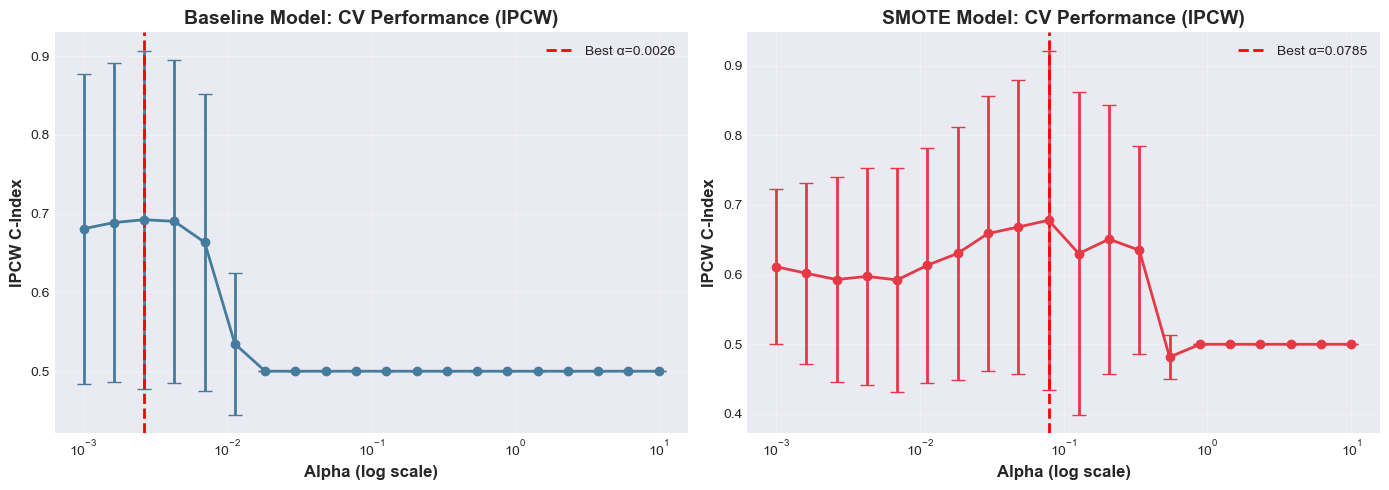


CV Summary Statistics:
Baseline - Best: 0.6924, Range: [0.5000, 0.6924]
SMOTE    - Best: 0.6781, Range: [0.4816, 0.6781]


In [52]:
# Visualize CV results for both models
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Baseline CV curve
axes[0].errorbar(cv_df_baseline['alpha'], cv_df_baseline['mean_c_index_ipcw'], 
                 yerr=cv_df_baseline['std_c_index_ipcw'], fmt='o-', capsize=5, 
                 color='#457B9D', linewidth=2, markersize=6)
axes[0].axvline(best_alpha_baseline, color='red', linestyle='--', linewidth=2, 
                label=f'Best α={best_alpha_baseline:.4f}')
axes[0].set_xscale('log')
axes[0].set_xlabel('Alpha (log scale)', fontsize=12, fontweight='bold')
axes[0].set_ylabel('IPCW C-Index', fontsize=12, fontweight='bold')
axes[0].set_title('Baseline Model: CV Performance (IPCW)', fontsize=14, fontweight='bold')
axes[0].legend()
axes[0].grid(alpha=0.3)

# SMOTE CV curve
axes[1].errorbar(cv_df_smote['alpha'], cv_df_smote['mean_c_index_ipcw'], 
                 yerr=cv_df_smote['std_c_index_ipcw'], fmt='o-', capsize=5, 
                 color='#E63946', linewidth=2, markersize=6)
axes[1].axvline(best_alpha_smote, color='red', linestyle='--', linewidth=2, 
                label=f'Best α={best_alpha_smote:.4f}')
axes[1].set_xscale('log')
axes[1].set_xlabel('Alpha (log scale)', fontsize=12, fontweight='bold')
axes[1].set_ylabel('IPCW C-Index', fontsize=12, fontweight='bold')
axes[1].set_title('SMOTE Model: CV Performance (IPCW)', fontsize=14, fontweight='bold')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Print summary statistics
print("\nCV Summary Statistics:")
print(f"Baseline - Best: {best_score_baseline:.4f}, Range: [{cv_df_baseline['mean_c_index_ipcw'].min():.4f}, {cv_df_baseline['mean_c_index_ipcw'].max():.4f}]")
print(f"SMOTE    - Best: {best_score_smote:.4f}, Range: [{cv_df_smote['mean_c_index_ipcw'].min():.4f}, {cv_df_smote['mean_c_index_ipcw'].max():.4f}]")

In [75]:
# Train Cox model on SMOTE-balanced data using best alpha from CV
print(f"Training Cox model WITH SMOTE using alpha={best_alpha_smote:.4f}...")

# Create structured array for sksurv (SMOTE-augmented labels)
y_train_smote = Surv.from_arrays(
    event=event_train_smote.astype(bool),
    time=time_train_smote
)

# Train Cox model on balanced data using Coxnet (Lasso) with best alpha
cox_smote = CoxnetSurvivalAnalysis(alphas=[best_alpha_smote], l1_ratio=1.0, fit_baseline_model=True)
cox_smote.fit(X_train_smote, y_train_smote)

# Predictions
# For training performance use the SMOTE training set (consistent with training)
train_risk_smote = cox_smote.predict(X_train_smote)
# For test predictions use the original scaled test set
test_risk_smote = cox_smote.predict(X_test_scaled)

# Evaluation
train_cindex_smote = concordance_index_censored(
    event_train_smote.astype(bool), time_train_smote, train_risk_smote
)[0]
test_cindex_smote = concordance_index_censored(
    event_test.astype(bool), time_test, test_risk_smote
)[0]

# IPCW C-Index
# Use original training survival (y_train) to estimate censoring for IPCW
max_time_ipcw = min(y_train['time'].max(), y_test['time'].max()) * 0.9
test_cindex_ipcw_smote, _, _, _, _ = concordance_index_ipcw(
    y_train, y_test, test_risk_smote, tau=max_time_ipcw
)

# Report number of selected features
n_features_smote = np.sum(cox_smote.coef_.flatten() != 0)

print(f"\n{'='*60}")
print("Cox Model WITH SMOTE Results")
print(f"{'='*60}")
print(f"Alpha used:          {best_alpha_smote:.4f}")
print(f"Features selected:   {n_features_smote}/{len(cox_smote.coef_.flatten())}")
print(f"Train C-Index:       {train_cindex_smote:.4f}")
print(f"Test C-Index:        {test_cindex_smote:.4f}")
print(f"Test C-Index (IPCW): {test_cindex_ipcw_smote:.4f}")
print(f"{'='*60}")

Training Cox model WITH SMOTE using alpha=0.0070...

Cox Model WITH SMOTE Results
Alpha used:          0.0070
Features selected:   36/69
Train C-Index:       0.9775
Test C-Index:        0.7231
Test C-Index (IPCW): 0.5671

Cox Model WITH SMOTE Results
Alpha used:          0.0070
Features selected:   36/69
Train C-Index:       0.9775
Test C-Index:        0.7231
Test C-Index (IPCW): 0.5671


## Comparison: Baseline vs SMOTE

In [76]:
# Create comparison table
comparison_df = pd.DataFrame({
    'Metric': ['Train C-Index', 'Test C-Index', 'Test C-Index (IPCW)'],
    'Baseline (No SMOTE)': [
        f"{train_cindex_baseline:.4f}",
        f"{test_cindex_baseline:.4f}",
        f"{test_cindex_ipcw_baseline:.4f}"
    ],
    'With SMOTE': [
        f"{train_cindex_smote:.4f}",
        f"{test_cindex_smote:.4f}",
        f"{test_cindex_ipcw_smote:.4f}"
    ],
    'Difference': [
        f"{train_cindex_smote - train_cindex_baseline:+.4f}",
        f"{test_cindex_smote - test_cindex_baseline:+.4f}",
        f"{test_cindex_ipcw_smote - test_cindex_ipcw_baseline:+.4f}"
    ]
})

print("\n" + "="*80)
print("COMPARISON: Baseline vs SMOTE")
print("="*80)
print(comparison_df.to_string(index=False))
print("="*80)

# Interpretation
test_improvement = test_cindex_smote - test_cindex_baseline
if test_improvement > 0.01:
    print(f"\n✓ SMOTE IMPROVED performance by {test_improvement:.4f}!")
    print("  → Better discrimination of events in test set")
elif test_improvement < -0.01:
    print(f"\n⚠ SMOTE DECREASED performance by {abs(test_improvement):.4f}")
    print("  → Original data balance may be appropriate")
else:
    print(f"\n≈ SMOTE had MINIMAL effect ({test_improvement:.4f})")
    print("  → Class imbalance may not be the limiting factor")


COMPARISON: Baseline vs SMOTE
             Metric Baseline (No SMOTE) With SMOTE Difference
      Train C-Index              0.9250     0.9775    +0.0526
       Test C-Index              0.8101     0.7231    -0.0870
Test C-Index (IPCW)              0.6242     0.5671    -0.0571

⚠ SMOTE DECREASED performance by 0.0870
  → Original data balance may be appropriate


## Visualize Performance Comparison

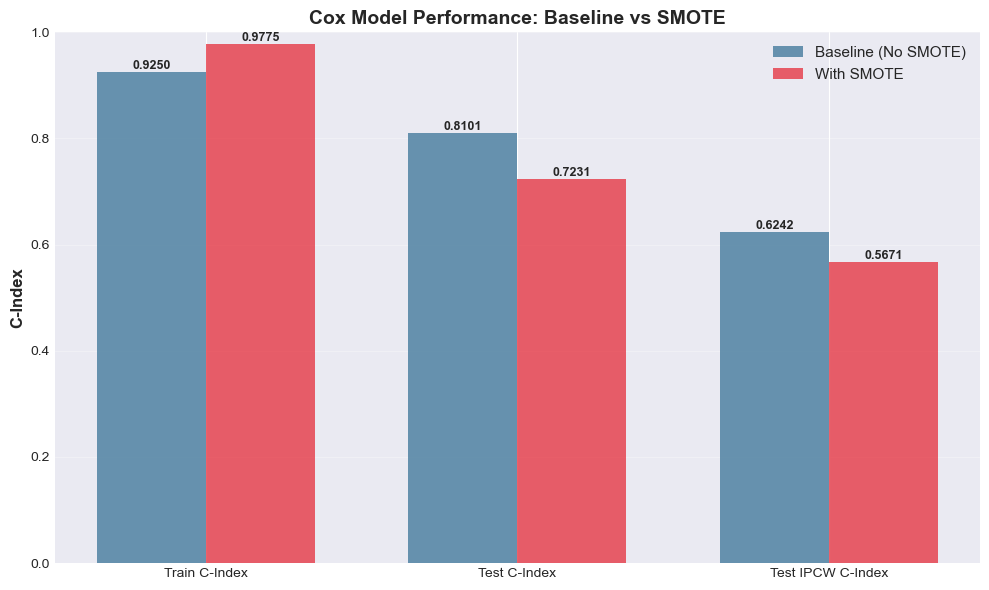

In [77]:
# Bar plot comparison
fig, ax = plt.subplots(figsize=(10, 6))

metrics = ['Train C-Index', 'Test C-Index', 'Test IPCW C-Index']
baseline_scores = [train_cindex_baseline, test_cindex_baseline, test_cindex_ipcw_baseline]
smote_scores = [train_cindex_smote, test_cindex_smote, test_cindex_ipcw_smote]

x = np.arange(len(metrics))
width = 0.35

bars1 = ax.bar(x - width/2, baseline_scores, width, label='Baseline (No SMOTE)', 
               color='#457B9D', alpha=0.8)
bars2 = ax.bar(x + width/2, smote_scores, width, label='With SMOTE',
               color='#E63946', alpha=0.8)

ax.set_ylabel('C-Index', fontsize=12, fontweight='bold')
ax.set_title('Cox Model Performance: Baseline vs SMOTE', fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(metrics)
ax.legend(fontsize=11)
ax.grid(axis='y', alpha=0.3)
ax.set_ylim([0, 1])

# Add value labels on bars
for bars in [bars1, bars2]:
    for bar in bars:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height,
                f'{height:.4f}',
                ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()

## Feature Importance Analysis (SMOTE Model)

In [56]:
# Get coefficients from SMOTE Cox model
coef = cox_smote.coef_.flatten()
feature_names = data_x.columns.tolist()

# Create dataframe
coef_df = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': coef,
    'Abs_Coefficient': np.abs(coef),
    'Hazard_Ratio': np.exp(coef)
})

# Sort by absolute coefficient
coef_df = coef_df.sort_values('Abs_Coefficient', ascending=False)

print("\nTop 20 Most Important Features:")
print("="*80)
print(coef_df.head(20).to_string(index=False))
print("="*80)


Top 20 Most Important Features:
                               Feature  Coefficient  Abs_Coefficient  Hazard_Ratio
   Oestrogen receptor status at CB_2.0    -0.366405         0.366405      0.693222
       Adjuvant therapy with bio drugs    -0.279809         0.279809      0.755928
   Oestrogen receptor status at CB_1.0     0.250921         0.250921      1.285209
         Endocrine therapy performed_1     0.240611         0.240611      1.272026
           Radiotherapy (RT) performed    -0.188662         0.188662      0.828066
          Conventional RT fraction_3.0    -0.137237         0.137237      0.871763
                      Istotype at CB_1    -0.026227         0.026227      0.974114
         N (Regional nodes affected)_2     0.009537         0.009537      1.009582
                         SLN procedure    -0.004667         0.004667      0.995344
          Type of 1st intervention_2.0     0.000000         0.000000      1.000000
                            cT_unknown     0.000000   

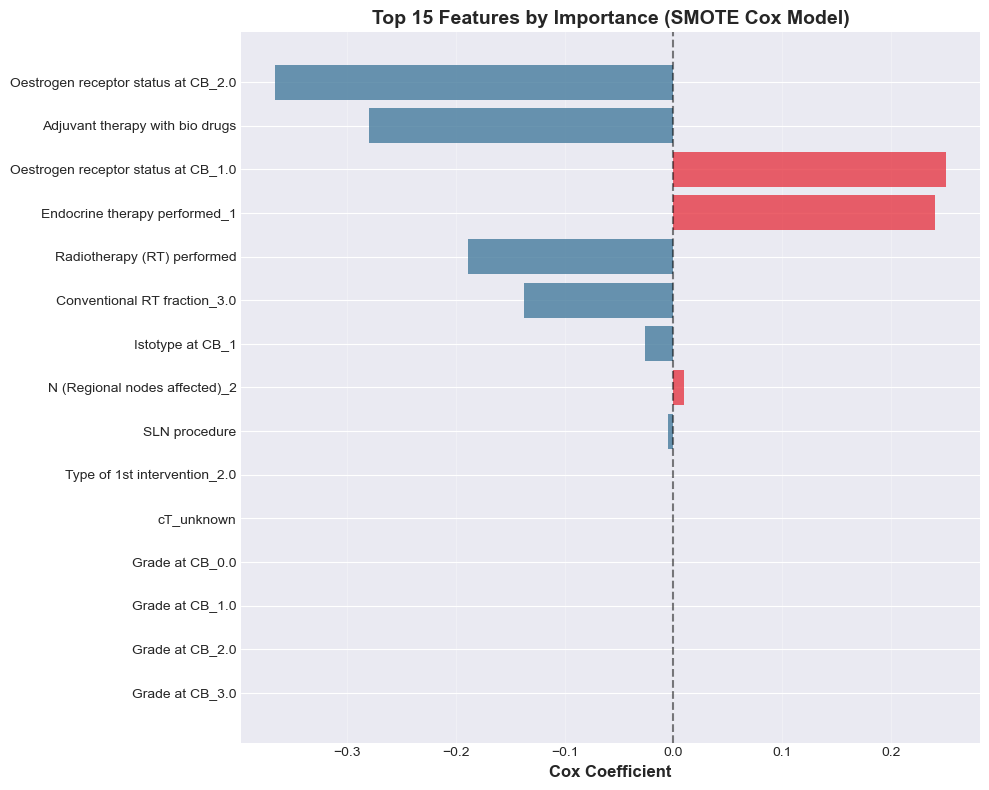


Interpretation:
  Red bars (positive): Increase hazard (worse prognosis)
  Blue bars (negative): Decrease hazard (better prognosis)


In [57]:
# Visualize top features
top_n = 15
top_features = coef_df.head(top_n).copy()

plt.figure(figsize=(10, 8))
colors = ['#E63946' if c > 0 else '#457B9D' for c in top_features['Coefficient']]
plt.barh(range(top_n), top_features['Coefficient'], color=colors, alpha=0.8)
plt.yticks(range(top_n), top_features['Feature'])
plt.xlabel('Cox Coefficient', fontsize=12, fontweight='bold')
plt.title(f'Top {top_n} Features by Importance (SMOTE Cox Model)', fontsize=14, fontweight='bold')
plt.axvline(x=0, color='black', linestyle='--', alpha=0.5)
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.gca().invert_yaxis()
plt.show()

print("\nInterpretation:")
print("  Red bars (positive): Increase hazard (worse prognosis)")
print("  Blue bars (negative): Decrease hazard (better prognosis)")

## Kaplan-Meier Curves (SMOTE Model)

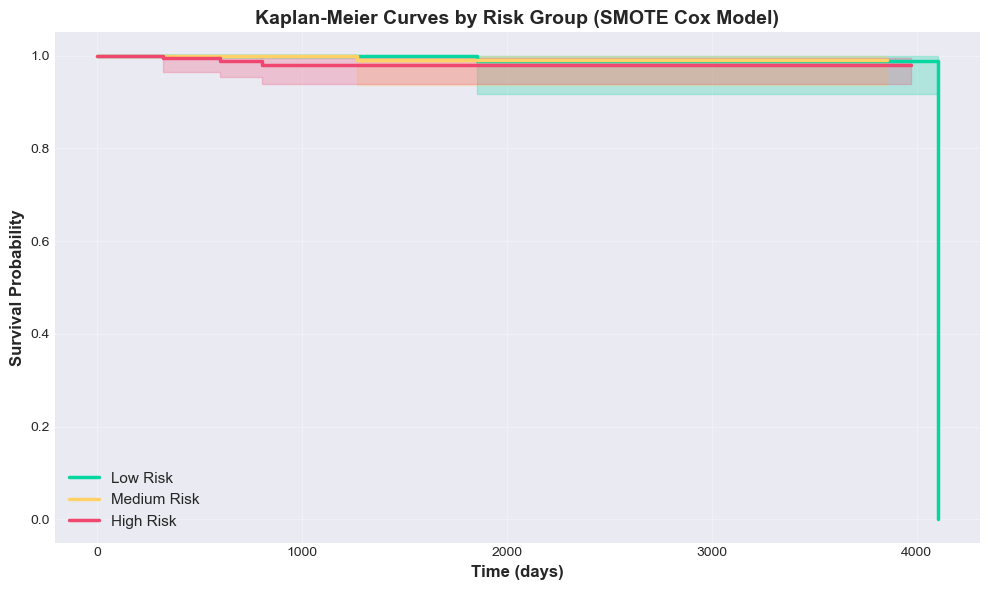


Log-Rank Tests (pairwise):
Low Risk vs Medium Risk:
  Test statistic: 0.0170
  p-value:        8.9621e-01
  Significant:    No

Low Risk vs High Risk:
  Test statistic: 1.3222
  p-value:        2.5019e-01
  Significant:    No

Medium Risk vs High Risk:
  Test statistic: 1.1334
  p-value:        2.8705e-01
  Significant:    No



In [78]:
# Stratify patients by risk (using SMOTE model predictions)
risk_tertiles = np.percentile(test_risk_smote, [33, 67])
risk_groups = np.digitize(test_risk_smote, risk_tertiles)

# Plot Kaplan-Meier curves for each risk group
fig, ax = plt.subplots(figsize=(10, 6))

kmf = KaplanMeierFitter()
colors = ['#06D6A0', '#FFD166', '#EF476F']
labels = ['Low Risk', 'Medium Risk', 'High Risk']

for i in range(3):
    mask = (risk_groups == i)
    kmf.fit(time_test[mask], event_test[mask], label=labels[i])
    kmf.plot_survival_function(ax=ax, color=colors[i], linewidth=2.5)

ax.set_xlabel('Time (days)', fontsize=12, fontweight='bold')
ax.set_ylabel('Survival Probability', fontsize=12, fontweight='bold')
ax.set_title('Kaplan-Meier Curves by Risk Group (SMOTE Cox Model)', fontsize=14, fontweight='bold')
ax.legend(fontsize=11, loc='best')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Log-rank test
print("\nLog-Rank Tests (pairwise):")
print("="*60)
for i in range(3):
    for j in range(i+1, 3):
        mask_i = (risk_groups == i)
        mask_j = (risk_groups == j)
        
        result = logrank_test(
            time_test[mask_i], time_test[mask_j],
            event_test[mask_i], event_test[mask_j]
        )
        
        print(f"{labels[i]} vs {labels[j]}:")
        print(f"  Test statistic: {result.test_statistic:.4f}")
        print(f"  p-value:        {result.p_value:.4e}")
        print(f"  Significant:    {'Yes' if result.p_value < 0.05 else 'No'}")
        print()

## Model Summary and Recommendations

In [59]:
print("\n" + "="*80)
print("FINAL SUMMARY")
print("="*80)

print("\n1. DATA CHARACTERISTICS:")
print(f"   - Total samples: {len(survival_dataset)}")
print(f"   - Features: {len(feature_columns)}")
print(f"   - Event rate: {survival_dataset['Regional LN recurrence'].mean()*100:.2f}%")
event_count = survival_dataset['Regional LN recurrence'].sum()
non_event_count = len(survival_dataset) - event_count
print(f"   - Imbalance ratio: 1:{non_event_count/event_count:.1f}")

print("\n2. SMOTE APPLICATION:")
print(f"   - Strategy: Oversample minority class to 50% of majority")
print(f"   - Samples added: {len(X_train_smote) - len(X_train_scaled)}")
print(f"   - New ratio: 1:{(1-event_train_smote).sum()/event_train_smote.sum():.1f}")

print("\n3. MODEL PERFORMANCE:")
print(f"   WITHOUT SMOTE:")
print(f"     - Test C-Index:        {test_cindex_baseline:.4f}")
print(f"     - Test C-Index (IPCW): {test_cindex_ipcw_baseline:.4f}")
print(f"   WITH SMOTE:")
print(f"     - Test C-Index:        {test_cindex_smote:.4f}")
print(f"     - Test C-Index (IPCW): {test_cindex_ipcw_smote:.4f}")
print(f"   IMPROVEMENT: {test_cindex_smote - test_cindex_baseline:+.4f}")

print("\n4. RECOMMENDATIONS:")
if test_cindex_smote > test_cindex_baseline + 0.01:
    print("   ✓ USE SMOTE MODEL: Significant improvement in discrimination")
    print("   ✓ Class imbalance was limiting baseline performance")
elif test_cindex_smote < test_cindex_baseline - 0.01:
    print("   ✓ USE BASELINE MODEL: SMOTE decreased performance")
    print("   ✓ Original data balance is appropriate for this problem")
else:
    print("   ≈ BOTH MODELS SIMILAR: Choose based on other criteria")
    print("   ≈ Consider other approaches (feature engineering, ensemble methods)")

print("\n" + "="*80)


FINAL SUMMARY

1. DATA CHARACTERISTICS:
   - Total samples: 2970
   - Features: 69
   - Event rate: 1.11%
   - Imbalance ratio: 1:89.0

2. SMOTE APPLICATION:
   - Strategy: Oversample minority class to 50% of majority
   - Samples added: 1147
   - New ratio: 1:2.0

3. MODEL PERFORMANCE:
   WITHOUT SMOTE:
     - Test C-Index:        0.8101
     - Test C-Index (IPCW): 0.6242
   WITH SMOTE:
     - Test C-Index:        0.7774
     - Test C-Index (IPCW): 0.6008
   IMPROVEMENT: -0.0328

4. RECOMMENDATIONS:
   ✓ USE BASELINE MODEL: SMOTE decreased performance
   ✓ Original data balance is appropriate for this problem

